# IP-Adapter 생성 비교

01 비교는 텍스트 프롬프트만 넣어 각 모델의 기본 그림체로 생성했다. 서비스는 게임마다 참조 이미지를 IP-Adapter로 넣어 그림체를 맞추므로, IP-Adapter 로드에 성공한 6개 모델에 게임별 참조 이미지를 넣어 생성하고 우리 데이터와의 그림체 유사도로 비교한다.

| 항목 | 조건 |
|---|---|
| 모델 | sdxl_base, animagine_xl4, playground_v25, sd35_large_turbo, flux1_schnell, sd35_large (01 `ipa_load.csv`에서 로드 성공) |
| 참조 이미지 | 03 EDA 6-6 대표성 1위: NAI `gen_0053`, KayKit `kk_0185`, 0x72 `x72_scene_0454` |
| IP-Adapter 강도 | 0.5 / 0.8 / 1.0 |
| 프롬프트 | 게임 데이터 프롬프트 (NAI `prompts.csv`, KayKit `renders_index.csv`, 0x72 `scene_log.csv`) |
| seed | 0, 1, 2 |
| 지표 | CLIP 이미지 임베딩 코사인 유사도: 참조 이미지와의 유사도, 참조·프롬프트에 쓰지 않은 게임 이미지 100장과의 평균 유사도 |

- 모델 1개 = 별도 프로세스 1개. 메모리 부족으로 프로세스가 죽어도 커널은 남고 다음 모델로 넘어간다.
- 측정값은 1장마다 `ipa_gen.csv`에 바로 추가한다. 다시 실행하면 기록과 PNG가 있는 조합은 건너뛴다.
- 모델 캐시는 측정 후 삭제한다(01과 같은 방식). IP-Adapter 가중치 캐시는 남긴다.

## Hugging Face 로그인

In [1]:
from huggingface_hub import login

login()

## 설정

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Multiple distributions found for package optimum. Picked distribution: optimum
W1020 18:19:58.505000 37664 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1020 18:19:58.621000 37664 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading 

[nai] no humans, black cat adventurer, yellow eyes, red wide-brim hat, ears through headwear, olive green capelet, brown cross-shaped clasp, brown belt, short sword at hip, olive green cape with shield emblem, standing upright, looking at viewer, green fields with a dirt road, daytime, full body, wide shot, flat color, cel shading, clean thin lineart, soft bright colors, storybook fantasy, anime style, very aesthetic, masterpiece, no text

[kaykit] low poly 3d game character render, barbarian, 1h melee attack chop, holding 1h axe, full body, plain background

[x72] pixel art, top-down view of a 16-bit dungeon room, flask big red, column, flask blue, coin, dwarf f run, skelet run, crate, hud hearts



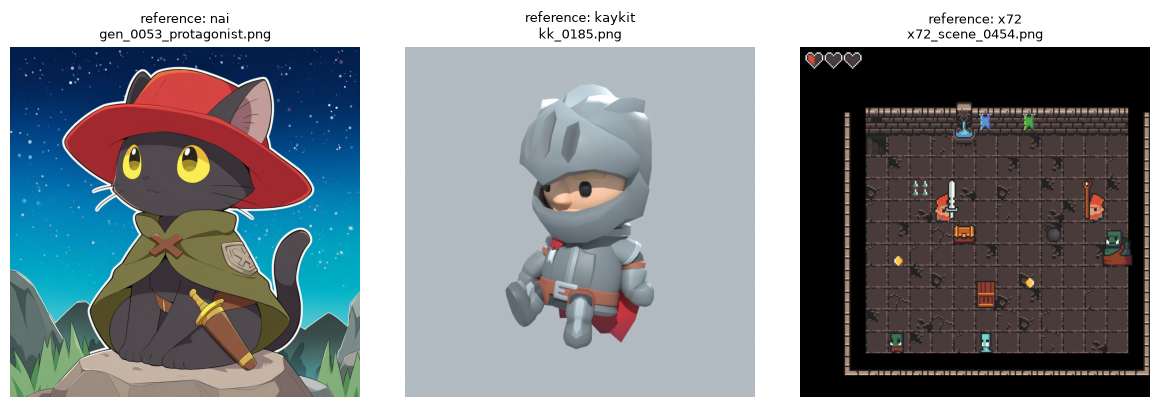

In [2]:
import json
import os
import shutil
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from diffusers import DiffusionPipeline
from huggingface_hub import scan_cache_dir, snapshot_download
from huggingface_hub.constants import HF_HUB_CACHE
from PIL import Image

RAW = Path('../data/raw')
OUT_DIR = Path('../outputs/ipa_compare')
OUT_DIR.mkdir(parents=True, exist_ok=True)
RECORDS_CSV = OUT_DIR / 'ipa_gen.csv'
RUNS_CSV = OUT_DIR / 'ipa_runs.csv'

# 01 비교 설정과 같은 값 (steps·cfg None = 파이프라인 기본값, offload = sequential CPU 오프로드)
MODELS = {
    'sdxl_base':        dict(repo='stabilityai/stable-diffusion-xl-base-1.0', steps=None, cfg=None, offload=False, ipa='sdxl'),
    'animagine_xl4':    dict(repo='cagliostrolab/animagine-xl-4.0', steps=None, cfg=None, offload=False, ipa='sdxl'),
    'playground_v25':   dict(repo='playgroundai/playground-v2.5-1024px-aesthetic', steps=None, cfg=None, offload=False, ipa='sdxl'),
    'sd35_large_turbo': dict(repo='stabilityai/stable-diffusion-3.5-large-turbo', steps=4, cfg=0.0, offload=True, ipa='sd3'),
    'flux1_schnell':    dict(repo='black-forest-labs/FLUX.1-schnell', steps=4, cfg=0.0, offload=True, ipa='flux'),
    'sd35_large':       dict(repo='stabilityai/stable-diffusion-3.5-large', steps=None, cfg=None, offload=True, ipa='sd3'),
}

# 01 `IPA`와 같은 가중치 (01에서 6개 모두 로드 성공)
IPA = {
    'sdxl': dict(repo='h94/IP-Adapter', kwargs=dict(subfolder='sdxl_models', weight_name='ip-adapter_sdxl.bin'),
                 files=[('h94/IP-Adapter', ['sdxl_models/ip-adapter_sdxl.bin', 'sdxl_models/image_encoder/*'], None)]),
    'sd3': dict(repo='InstantX/SD3.5-Large-IP-Adapter',
                kwargs=dict(weight_name='ip-adapter.bin', image_encoder_folder='google/siglip-so400m-patch14-384'),
                files=[('InstantX/SD3.5-Large-IP-Adapter', ['ip-adapter.bin'], None),
                       ('google/siglip-so400m-patch14-384', ['*.json', '*.safetensors', '*.model', '*.txt'], None)]),
    'flux': dict(repo='XLabs-AI/flux-ip-adapter',
                 kwargs=dict(weight_name='ip_adapter.safetensors', image_encoder_pretrained_model_name_or_path='openai/clip-vit-large-patch14'),
                 files=[('XLabs-AI/flux-ip-adapter', ['ip_adapter.safetensors'], None),
                        ('openai/clip-vit-large-patch14', ['*.json', '*.safetensors', '*.txt'], None)]),
}

GAME_DIRS = {'nai': RAW / 'nai' / 'lora_gen', 'kaykit': RAW / 'kaykit' / 'renders', 'x72': RAW / 'pixel_0x72' / 'scenes'}
# 03 EDA 6-6 대표성 1위 (CLIP 임베딩 평균에 가장 가까운 이미지)
REFS = {'nai': GAME_DIRS['nai'] / 'gen_0053_protagonist.png',
        'kaykit': GAME_DIRS['kaykit'] / 'kk_0185.png',
        'x72': GAME_DIRS['x72'] / 'x72_scene_0454.png'}
SCALES = [0.5, 0.8, 1.0]
# 값 자체는 의미 없음. 01과 같은 seed
SEEDS = [0, 1, 2]

# 프롬프트는 참조 이미지와 다른 이미지의 데이터에서 가져옴 → 참조 이미지를 그대로 베끼는지와 그림체만 옮기는지 구분
PROMPT_SRC = {'nai': 'gen_0000_protagonist.png', 'kaykit': 'kk_0000.png', 'x72': 'x72_scene_0000.png'}
nai_info = pd.read_csv(GAME_DIRS['nai'] / 'prompts.csv').set_index('file')
kk_info = pd.read_csv(GAME_DIRS['kaykit'] / 'renders_index.csv').set_index('short_name')
x72_info = pd.read_csv(GAME_DIRS['x72'] / 'scene_log.csv').set_index('file')

k = kk_info.loc[PROMPT_SRC['kaykit']]
x = x72_info.loc[PROMPT_SRC['x72']]
ents = list(dict.fromkeys(e.replace('_', ' ') for e in x['entities'].split('|')))
PROMPTS = {
    'nai': nai_info.loc[PROMPT_SRC['nai'], 'prompt'],
    'kaykit': (f"low poly 3d game character render, {k['character'].replace('_', ' ').lower()}, "
               f"{k['action'].replace('_', ' ').lower()}"
               + (f", holding {k['props'].replace('_', ' ').replace('+', ' and ').lower()}" if isinstance(k['props'], str) else '')
               + ', full body, plain background'),
    'x72': 'pixel art, top-down view of a 16-bit dungeon room, ' + ', '.join(ents),
}
for g, p in PROMPTS.items():
    print(f'[{g}] {p}\n')

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (g, path) in zip(axes, REFS.items()):
    ax.imshow(Image.open(path).convert('RGB'))
    ax.set_title(f'reference: {g}\n{path.name}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.savefig(OUT_DIR / 'references.png', dpi=80)
plt.show()

## 디스크 확인

모델을 1개씩 받아 측정한 뒤 캐시에서 삭제한다. 6개 저장소 합계는 01 기록 기준 약 115.5GB다(sdxl_base 13.24, animagine_xl4 6.46, playground_v25 12.93, sd35_large_turbo 25.73, flux1_schnell 31.41, sd35_large 25.73).

In [3]:
def free_gb():
    return shutil.disk_usage(HF_HUB_CACHE).free / 1024**3


def cached_repo(repo_id):
    return next((r for r in scan_cache_dir().repos if r.repo_id == repo_id), None)


def delete_cached(repo_id):
    r = cached_repo(repo_id)
    if r is None:
        return 0.0
    size = r.size_on_disk / 1024**3
    scan_cache_dir().delete_revisions(*[rev.commit_hash for rev in r.revisions]).execute()
    return size


print(f'free: {free_gb():.1f} GB')
# 가장 큰 저장소(flux1_schnell 31.41GB) + IP-Adapter 가중치보다 여유가 적으면 중간에 찰 수 있음
assert free_gb() > 50, '디스크 여유 공간이 50GB 미만'

from huggingface_hub import auth_check
from huggingface_hub.errors import GatedRepoError
for repo in sorted({c['repo'] for c in MODELS.values()} | {r for s in IPA.values() for r, _, _ in s['files']}):
    try:
        auth_check(repo)
        print(f'OK     {repo}')
    except GatedRepoError:
        print(f'GATED  {repo}')

free: 166.5 GB
OK     InstantX/SD3.5-Large-IP-Adapter
OK     XLabs-AI/flux-ip-adapter
OK     black-forest-labs/FLUX.1-schnell
OK     cagliostrolab/animagine-xl-4.0
OK     google/siglip-so400m-patch14-384
OK     h94/IP-Adapter
OK     openai/clip-vit-large-patch14
OK     playgroundai/playground-v2.5-1024px-aesthetic
OK     stabilityai/stable-diffusion-3.5-large
OK     stabilityai/stable-diffusion-3.5-large-turbo
OK     stabilityai/stable-diffusion-xl-base-1.0


## 생성 및 측정

모델마다 별도 프로세스에서 다음 순서로 실행한다.

1. 파이프라인을 CPU에 로드하고 IP-Adapter를 붙인다. IP-Adapter 로더는 오프로드 훅을 풀지 않아서 오프로드를 켜기 전에 붙인다.
2. 오프로드(또는 GPU 이동)를 켠다. SD3 계열은 이미지 인코더(SigLIP)를 sequential 오프로드에서 빼고 GPU에 둔다(`pipeline_stable_diffusion_3.py` 762–768줄 경고).
3. 워밍업 1장(시간만 기록) 후 게임 3 × 강도 3 × seed 3 = 27장을 생성한다.

In [4]:
CHILD = r"""
import csv, json, sys, threading, time
from pathlib import Path
import psutil, torch
from diffusers import DiffusionPipeline
from PIL import Image

a = json.loads(sys.stdin.read())
cfg, spec = a['cfg'], a['spec']
out_dir = Path(a['out_dir'])
proc = psutil.Process()


class PeakRAM:
    def __enter__(self):
        self.peak = proc.memory_info().rss
        self.stop = threading.Event()
        def run():
            while not self.stop.wait(0.2):
                self.peak = max(self.peak, proc.memory_info().rss)
        self.t = threading.Thread(target=run, daemon=True)
        self.t.start()
        return self
    def __exit__(self, *e):
        self.stop.set()
        self.t.join()


def kwargs(prompt, seed, ref):
    k = dict(prompt=prompt, width=1024, height=1024, ip_adapter_image=ref,
             generator=torch.Generator('cpu').manual_seed(seed))
    if cfg['steps'] is not None:
        k['num_inference_steps'] = cfg['steps']
    if cfg['cfg'] is not None:
        k['guidance_scale'] = cfg['cfg']
    return k


with PeakRAM() as lr:
    t0 = time.perf_counter()
    pipe = DiffusionPipeline.from_pretrained(cfg['repo'], torch_dtype=torch.bfloat16)
    pipe.load_ip_adapter(spec['repo'], **spec['kwargs'])
    if cfg['ipa'] == 'sd3':
        pipe._exclude_from_cpu_offload.append('image_encoder')
    if cfg['offload']:
        pipe.enable_sequential_cpu_offload()
        if cfg['ipa'] == 'sd3':
            pipe.image_encoder.to('cuda')
    else:
        pipe.to('cuda')
    load_sec = round(time.perf_counter() - t0, 2)
print(f"LOAD {a['name']} {load_sec}s peak_ram={lr.peak / 1024**3:.2f}GB", flush=True)

refs = {g: Image.open(p).convert('RGB') for g, p in a['refs'].items()}
g0 = next(iter(a['prompts']))
pipe.set_ip_adapter_scale(a['scales'][0])
torch.cuda.synchronize()
t0 = time.perf_counter()
pipe(**kwargs(a['prompts'][g0], a['seeds'][0], refs[g0]))
torch.cuda.synchronize()
warmup = round(time.perf_counter() - t0, 2)
print(f"WARMUP {a['name']} {warmup}s", flush=True)

done = set(tuple(x) for x in a['done'])
for g, prompt in a['prompts'].items():
    for sc in a['scales']:
        pipe.set_ip_adapter_scale(sc)
        for seed in a['seeds']:
            if (g, sc, seed) in done:
                continue
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()
            with PeakRAM() as gr:
                t0 = time.perf_counter()
                img = pipe(**kwargs(prompt, seed, refs[g])).images[0]
                torch.cuda.synchronize()
                sec = round(time.perf_counter() - t0, 2)
            f = out_dir / f"{a['name']}_{g}_sc{sc}_s{seed}.png"
            img.save(f)
            rec = dict(model=a['name'], game=g, scale=sc, seed=seed, offload=cfg['offload'], sec=sec,
                       peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1024**3, 2),
                       peak_ram_gb=round(gr.peak / 1024**3, 2), warmup_sec=warmup, load_sec=load_sec,
                       load_peak_ram_gb=round(lr.peak / 1024**3, 2), file=f.name)
            new = not Path(a['records']).exists()
            with open(a['records'], 'a', newline='', encoding='utf-8') as fh:
                w = csv.DictWriter(fh, fieldnames=list(rec))
                if new:
                    w.writeheader()
                w.writerow(rec)
            print(f"GEN {a['name']} {g} sc{sc} s{seed} {sec}s vram={rec['peak_vram_gb']}GB ram={rec['peak_ram_gb']}GB", flush=True)
"""


def done_keys(name):
    if not RECORDS_CSV.exists():
        return set()
    r = pd.read_csv(RECORDS_CSV)
    r = r[r.model == name]
    return {(x.game, float(x.scale), int(x.seed)) for x in r.itertuples() if (OUT_DIR / x.file).exists()}


TOTAL = len(PROMPTS) * len(SCALES) * len(SEEDS)
for name, cfg in MODELS.items():
    done = done_keys(name)
    if len(done) >= TOTAL:
        print(f'{name:16s} skip ({len(done)}/{TOTAL})')
        continue
    spec = IPA[cfg['ipa']]
    t0 = time.perf_counter()
    DiffusionPipeline.download(cfg['repo'])
    for repo, patterns, rev in spec['files']:
        snapshot_download(repo, allow_patterns=patterns, revision=rev)
    dl_sec = round(time.perf_counter() - t0, 2)
    r = cached_repo(cfg['repo'])
    dl_gb = round(r.size_on_disk / 1024**3, 2) if r else None
    print(f'{name:16s} download {dl_sec}s ({dl_gb}GB)', flush=True)

    arg = json.dumps(dict(name=name, cfg=cfg, spec=spec, refs={g: str(p) for g, p in REFS.items()}, prompts=PROMPTS,
                          scales=SCALES, seeds=SEEDS, out_dir=str(OUT_DIR), records=str(RECORDS_CSV),
                          done=[list(d) for d in done]))
    p = subprocess.Popen([sys.executable, '-c', CHILD], stdin=subprocess.PIPE, stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace',
                         env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    p.stdin.write(arg)
    p.stdin.close()
    tail = []
    for line in p.stdout:
        line = line.rstrip()
        tail = (tail + [line])[-20:]
        if line.startswith(('LOAD', 'WARMUP', 'GEN', 'Traceback')) or 'Error' in line:
            print(line, flush=True)
    p.wait()
    n_done = len(done_keys(name))
    run = dict(model=name, returncode=p.returncode, images=n_done, download_sec=dl_sec, download_gb=dl_gb,
               error='' if p.returncode == 0 else ' | '.join(tail[-5:])[:500])
    pd.DataFrame([run]).to_csv(RUNS_CSV, mode='a', header=not RUNS_CSV.exists(), index=False, encoding='utf-8')
    deleted = delete_cached(cfg['repo'])
    print(f'{name:16s} exit={p.returncode} images={n_done}/{TOTAL} cache deleted {deleted:.1f}GB free {free_gb():.1f}GB\n', flush=True)

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Administrator\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\huggi

sdxl_base        download 117.86s (13.24GB)


LOAD sdxl_base 16.9s peak_ram=15.75GB
WARMUP sdxl_base 15.74s
GEN sdxl_base nai sc0.5 s0 15.21s vram=13.07GB ram=2.06GB
GEN sdxl_base nai sc0.5 s1 16.32s vram=13.07GB ram=2.04GB
GEN sdxl_base nai sc0.5 s2 16.75s vram=13.07GB ram=2.04GB
GEN sdxl_base nai sc0.8 s0 16.72s vram=13.07GB ram=2.04GB
GEN sdxl_base nai sc0.8 s1 17.16s vram=13.07GB ram=2.04GB
GEN sdxl_base nai sc0.8 s2 17.28s vram=13.07GB ram=2.04GB
GEN sdxl_base nai sc1.0 s0 16.76s vram=13.07GB ram=2.04GB
GEN sdxl_base nai sc1.0 s1 16.05s vram=13.07GB ram=2.04GB
GEN sdxl_base nai sc1.0 s2 15.71s vram=13.07GB ram=2.04GB
GEN sdxl_base kaykit sc0.5 s0 16.75s vram=13.07GB ram=2.04GB
GEN sdxl_base kaykit sc0.5 s1 17.01s vram=13.07GB ram=2.04GB
GEN sdxl_base kaykit sc0.5 s2 16.92s vram=13.07GB ram=2.04GB
GEN sdxl_base kaykit sc0.8 s0 16.97s vram=13.07GB ram=2.04GB
GEN sdxl_base kaykit sc0.8 s1 17.01s vram=13.07GB ram=2.04GB
GEN sdxl_base kaykit sc0.8 s2 16.99s vram=13.07GB ram=2.04GB
GEN sdxl_base kaykit sc1.0 s0 17.04s vram=13.07GB 

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Administrator\.cache\huggingface\hub\models--cagliostrolab--animagine-xl-4.0. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Fetching 4 files: 100%|█████

animagine_xl4    download 67.02s (6.46GB)


LOAD animagine_xl4 13.66s peak_ram=12.15GB
WARMUP animagine_xl4 16.71s
GEN animagine_xl4 nai sc0.5 s0 16.74s vram=13.07GB ram=1.92GB
GEN animagine_xl4 nai sc0.5 s1 17.01s vram=13.07GB ram=1.93GB
GEN animagine_xl4 nai sc0.5 s2 16.76s vram=13.07GB ram=1.93GB
GEN animagine_xl4 nai sc0.8 s0 17.03s vram=13.07GB ram=1.95GB
GEN animagine_xl4 nai sc0.8 s1 16.94s vram=13.07GB ram=1.93GB
GEN animagine_xl4 nai sc0.8 s2 16.85s vram=13.07GB ram=1.96GB
GEN animagine_xl4 nai sc1.0 s0 16.86s vram=13.07GB ram=1.95GB
GEN animagine_xl4 nai sc1.0 s1 17.01s vram=13.07GB ram=1.93GB
GEN animagine_xl4 nai sc1.0 s2 17.03s vram=13.07GB ram=1.93GB
GEN animagine_xl4 kaykit sc0.5 s0 17.33s vram=13.07GB ram=1.93GB
GEN animagine_xl4 kaykit sc0.5 s1 17.22s vram=13.07GB ram=1.93GB
GEN animagine_xl4 kaykit sc0.5 s2 16.96s vram=13.07GB ram=1.93GB
GEN animagine_xl4 kaykit sc0.8 s0 17.06s vram=13.07GB ram=1.94GB
GEN animagine_xl4 kaykit sc0.8 s1 17.06s vram=13.07GB ram=1.93GB
GEN animagine_xl4 kaykit sc0.8 s2 17.36s vram=

... (8 outputs left out)

LOAD flux1_schnell 10.12s peak_ram=10.69GB
WARMUP flux1_schnell 33.42s
GEN flux1_schnell nai sc0.5 s0 28.71s vram=2.39GB ram=34.97GB
GEN flux1_schnell nai sc0.5 s1 30.03s vram=2.39GB ram=34.97GB
GEN flux1_schnell nai sc0.5 s2 31.77s vram=2.39GB ram=34.97GB
GEN flux1_schnell nai sc0.8 s0 31.76s vram=2.39GB ram=34.97GB
GEN flux1_schnell nai sc0.8 s1 31.65s vram=2.39GB ram=34.97GB
GEN flux1_schnell nai sc0.8 s2 31.49s vram=2.39GB ram=34.97GB
GEN flux1_schnell nai sc1.0 s0 29.75s vram=2.39GB ram=34.97GB
GEN flux1_schnell nai sc1.0 s1 29.34s vram=2.39GB ram=34.97GB
GEN flux1_schnell nai sc1.0 s2 30.18s vram=2.39GB ram=34.97GB
GEN flux1_schnell kaykit sc0.5 s0 29.66s vram=2.39GB ram=34.97GB
GEN flux1_schnell kaykit sc0.5 s1 30.41s vram=2.39GB ram=34.97GB
GEN flux1_schnell kaykit sc0.5 s2 32.33s vram=2.39GB ram=34.97GB
GEN flux1_schnell kaykit sc0.8 s0 32.22s vram=2.39GB ram=34.97GB
GEN flux1_schnell kaykit sc0.8 s1 32.66s vram=2.39GB ram=34.97GB
GEN flux1_schnell kaykit sc0.8 s2 32.14s vram=

Fetching 28 files:   0%|          | 0/28 [00:00<?, ?it/s]c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Administrator\.cache\huggingface\hub\models--stabilityai--stable-diffusion-3.5-large. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Fetching 7 files: 10

sd35_large       download 253.09s (25.73GB)


LOAD sd35_large 18.98s peak_ram=15.04GB
WARMUP sd35_large 193.55s
GEN sd35_large nai sc0.5 s0 216.4s vram=3.38GB ram=29.14GB
GEN sd35_large nai sc0.5 s1 208.26s vram=3.38GB ram=29.13GB
GEN sd35_large nai sc0.5 s2 214.82s vram=3.38GB ram=29.14GB
GEN sd35_large nai sc0.8 s0 222.78s vram=3.38GB ram=29.13GB
GEN sd35_large nai sc0.8 s1 219.21s vram=3.38GB ram=29.14GB
GEN sd35_large nai sc0.8 s2 214.77s vram=3.38GB ram=29.13GB
GEN sd35_large nai sc1.0 s0 220.31s vram=3.38GB ram=29.14GB
GEN sd35_large nai sc1.0 s1 219.07s vram=3.38GB ram=28.44GB
GEN sd35_large nai sc1.0 s2 221.4s vram=3.38GB ram=28.45GB
GEN sd35_large kaykit sc0.5 s0 217.06s vram=3.38GB ram=28.38GB
GEN sd35_large kaykit sc0.5 s1 219.83s vram=3.38GB ram=27.71GB
GEN sd35_large kaykit sc0.5 s2 216.86s vram=3.38GB ram=27.69GB
GEN sd35_large kaykit sc0.8 s0 205.19s vram=3.38GB ram=27.71GB
GEN sd35_large kaykit sc0.8 s1 204.28s vram=3.38GB ram=27.51GB
GEN sd35_large kaykit sc0.8 s2 204.1s vram=3.38GB ram=27.48GB
GEN sd35_large kayk

## 그림체 유사도

03 EDA와 같은 CLIP(`openai/clip-vit-base-patch32`)으로 임베딩을 구한다.

- `ref_sim`: 생성 이미지와 참조 이미지의 코사인 유사도. 너무 높으면 참조 이미지를 베낀 것이다.
- `style_sim`: 생성 이미지와, 참조·프롬프트에 쓰지 않은 같은 게임 이미지 100장(seed 0 무작위)의 평균 코사인 유사도. 그림체를 얼마나 따라가는지 본다.

In [5]:
import numpy as np
import torch
from transformers import CLIPModel, CLIPProcessor

CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


@torch.no_grad()
def embed(paths, bs=32):
    out = []
    for i in range(0, len(paths), bs):
        x = clip_proc(images=[Image.open(p).convert('RGB') for p in paths[i:i + bs]], return_tensors='pt').to('cuda')
        # transformers 5.x: get_image_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
        e = clip.get_image_features(**x).pooler_output
        out.append(torch.nn.functional.normalize(e, dim=-1).float().cpu())
    return torch.cat(out).numpy()


rng = np.random.default_rng(0)
REF_EMB, HELD_EMB = {}, {}
for g, d in GAME_DIRS.items():
    pool = [p for p in sorted(d.glob('*.png')) if p.name not in (REFS[g].name, PROMPT_SRC[g])]
    held = [pool[i] for i in rng.choice(len(pool), 100, replace=False)]
    REF_EMB[g] = embed([REFS[g]])[0]
    HELD_EMB[g] = embed(held)

rec = pd.read_csv(RECORDS_CSV).drop_duplicates(['model', 'game', 'scale', 'seed'], keep='last')
E = embed([OUT_DIR / f for f in rec.file])
rec['ref_sim'] = [float(e @ REF_EMB[g]) for e, g in zip(E, rec.game)]
rec['style_sim'] = [float((HELD_EMB[g] @ e).mean()) for e, g in zip(E, rec.game)]
# 기준선: 같은 게임 이미지끼리의 평균 유사도 (생성 이미지가 이 값에 가까울수록 우리 데이터와 비슷)
base = {g: float((HELD_EMB[g] @ HELD_EMB[g].T)[~np.eye(100, dtype=bool)].mean()) for g in GAME_DIRS}
print('게임 내부 평균 유사도(기준선):', {g: round(v, 3) for g, v in base.items()})
rec.to_csv(OUT_DIR / 'ipa_gen_scored.csv', index=False, encoding='utf-8-sig')

summary = rec.groupby(['model', 'game', 'scale'], sort=False).agg(
    style_sim=('style_sim', 'mean'), ref_sim=('ref_sim', 'mean'), sec=('sec', 'mean'),
    vram=('peak_vram_gb', 'max'), ram=('peak_ram_gb', 'max')).round(3).reset_index()
summary.to_csv(OUT_DIR / 'ipa_gen_summary.csv', index=False, encoding='utf-8-sig')
display(summary.pivot_table(index='model', columns=['game', 'scale'], values='style_sim', sort=False).round(3))
display(summary.pivot_table(index='model', columns=['game', 'scale'], values='ref_sim', sort=False).round(3))
display(pd.read_csv(RUNS_CSV) if RUNS_CSV.exists() else None)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 20753.81it/s]


게임 내부 평균 유사도(기준선): {'nai': 0.711, 'kaykit': 0.836, 'x72': 0.949}


game                nai               kaykit                  x72         \
scale               0.5    0.8    1.0    0.5    0.8    1.0    0.5    0.8   
model                                                                      
sdxl_base         0.738  0.739  0.739  0.786  0.812  0.814  0.878  0.880   
animagine_xl4     0.728  0.727  0.715  0.787  0.791  0.770  0.845  0.801   
playground_v25    0.722  0.737  0.718  0.680  0.701  0.714  0.761  0.748   
sd35_large_turbo  0.738  0.740  0.749  0.790  0.814  0.817  0.868  0.862   
flux1_schnell     0.738  0.756  0.754  0.779  0.795  0.790  0.857  0.850   
sd35_large        0.742  0.754  0.740  0.804  0.813  0.817  0.864  0.869   

game                     
scale               1.0  
model                    
sdxl_base         0.887  
animagine_xl4     0.797  
playground_v25    0.720  
sd35_large_turbo  0.869  
flux1_schnell     0.866  
sd35_large        0.893

game                nai               kaykit                  x72         \
scale               0.5    0.8    1.0    0.5    0.8    1.0    0.5    0.8   
model                                                                      
sdxl_base         0.895  0.909  0.915  0.861  0.905  0.911  0.895  0.895   
animagine_xl4     0.869  0.886  0.863  0.859  0.870  0.835  0.857  0.809   
playground_v25    0.866  0.870  0.830  0.698  0.711  0.718  0.774  0.756   
sd35_large_turbo  0.895  0.916  0.925  0.850  0.896  0.904  0.879  0.868   
flux1_schnell     0.895  0.916  0.897  0.825  0.851  0.865  0.875  0.857   
sd35_large        0.917  0.934  0.928  0.885  0.904  0.907  0.870  0.876   

game                     
scale               1.0  
model                    
sdxl_base         0.901  
animagine_xl4     0.809  
playground_v25    0.725  
sd35_large_turbo  0.877  
flux1_schnell     0.873  
sd35_large        0.906

,model,returncode,images,download_sec,download_gb,error
0,sdxl_base,0,27,117.86,13.24,NaN
1,animagine_xl4,0,27,67.02,6.46,NaN
2,playground_v25,0,27,122.26,12.93,NaN
3,sd35_large_turbo,0,27,231.16,25.73,NaN
4,flux1_schnell,0,27,298.80,31.41,NaN
5,sd35_large,0,27,253.09,25.73,NaN


## 시각화

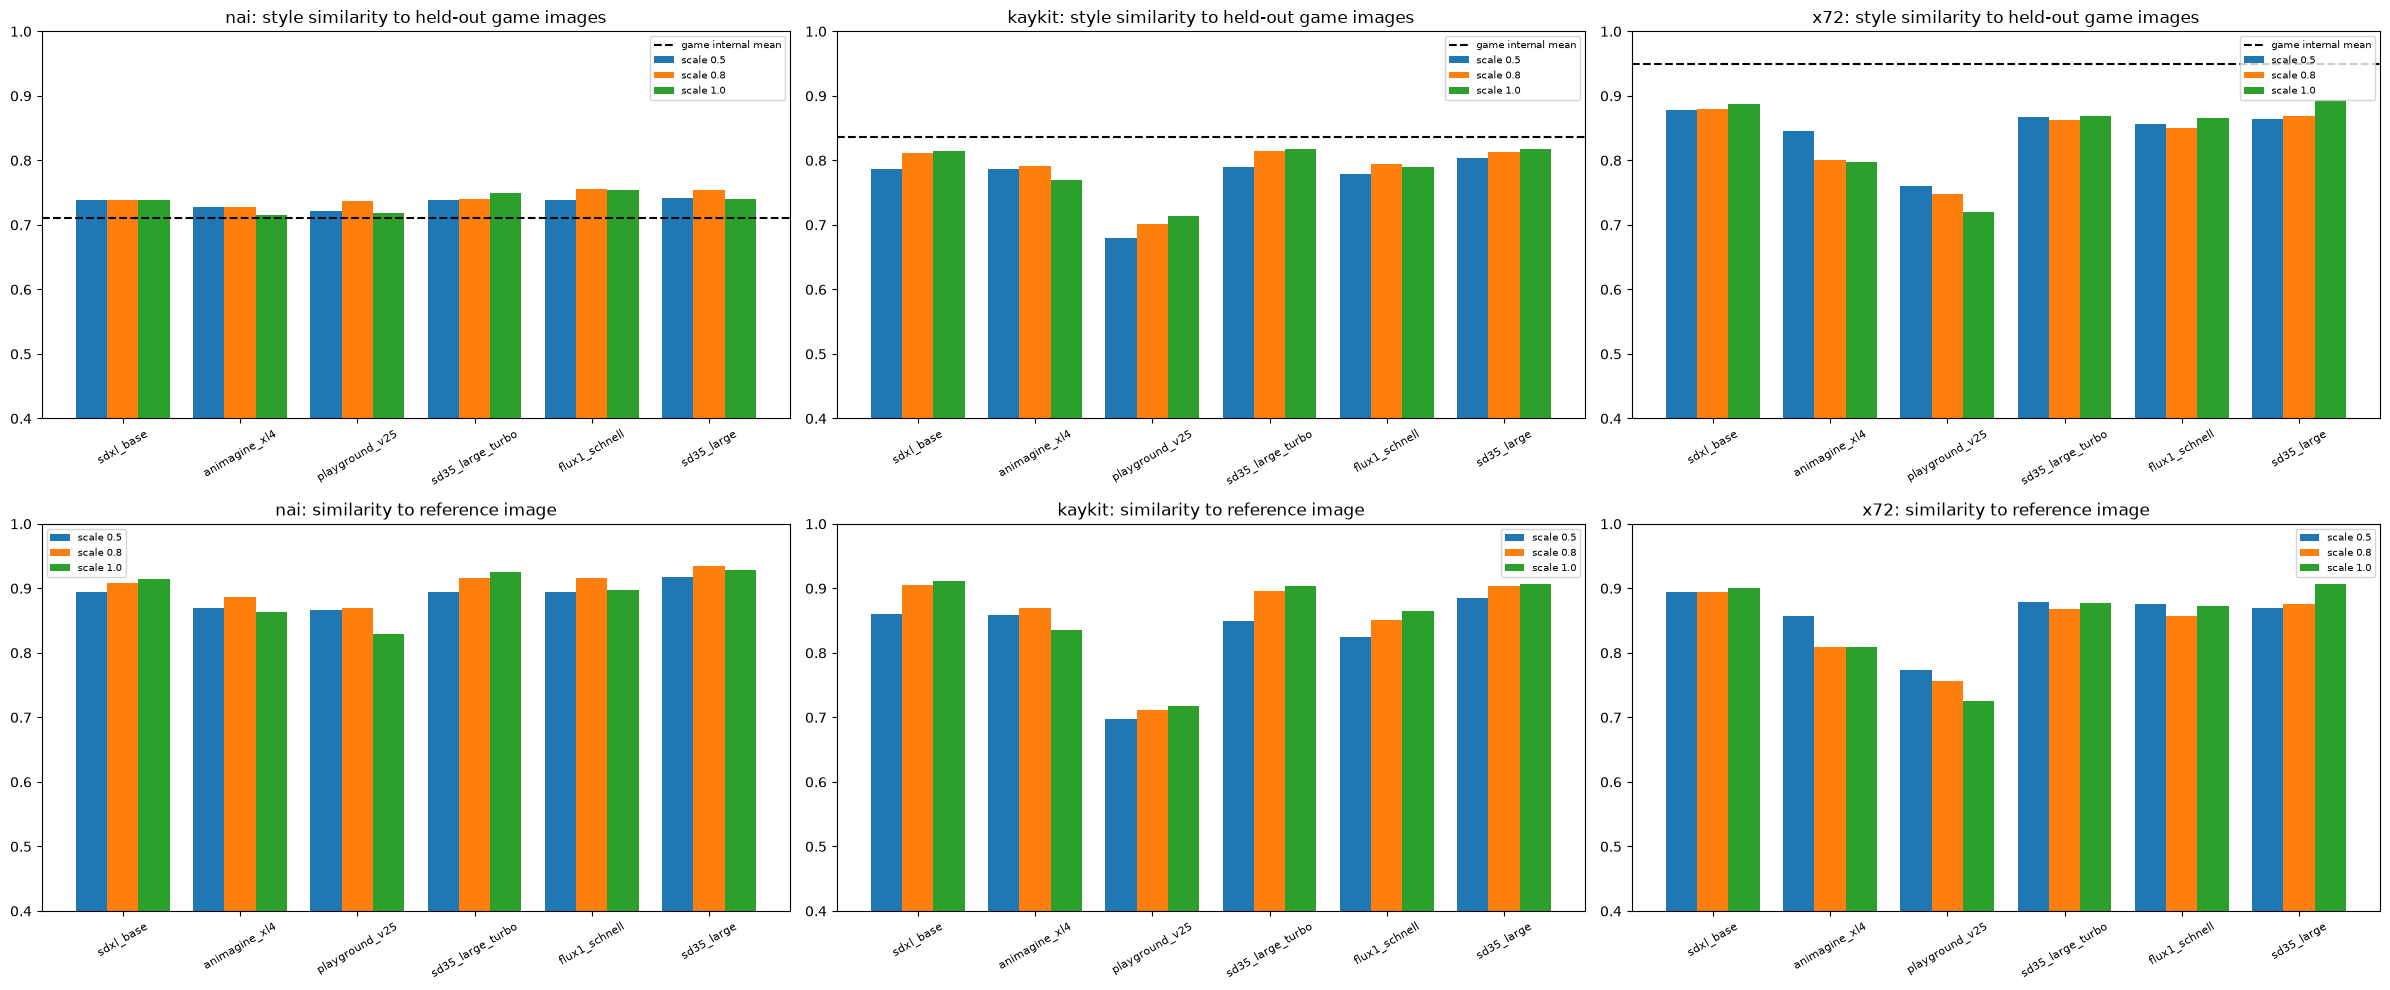

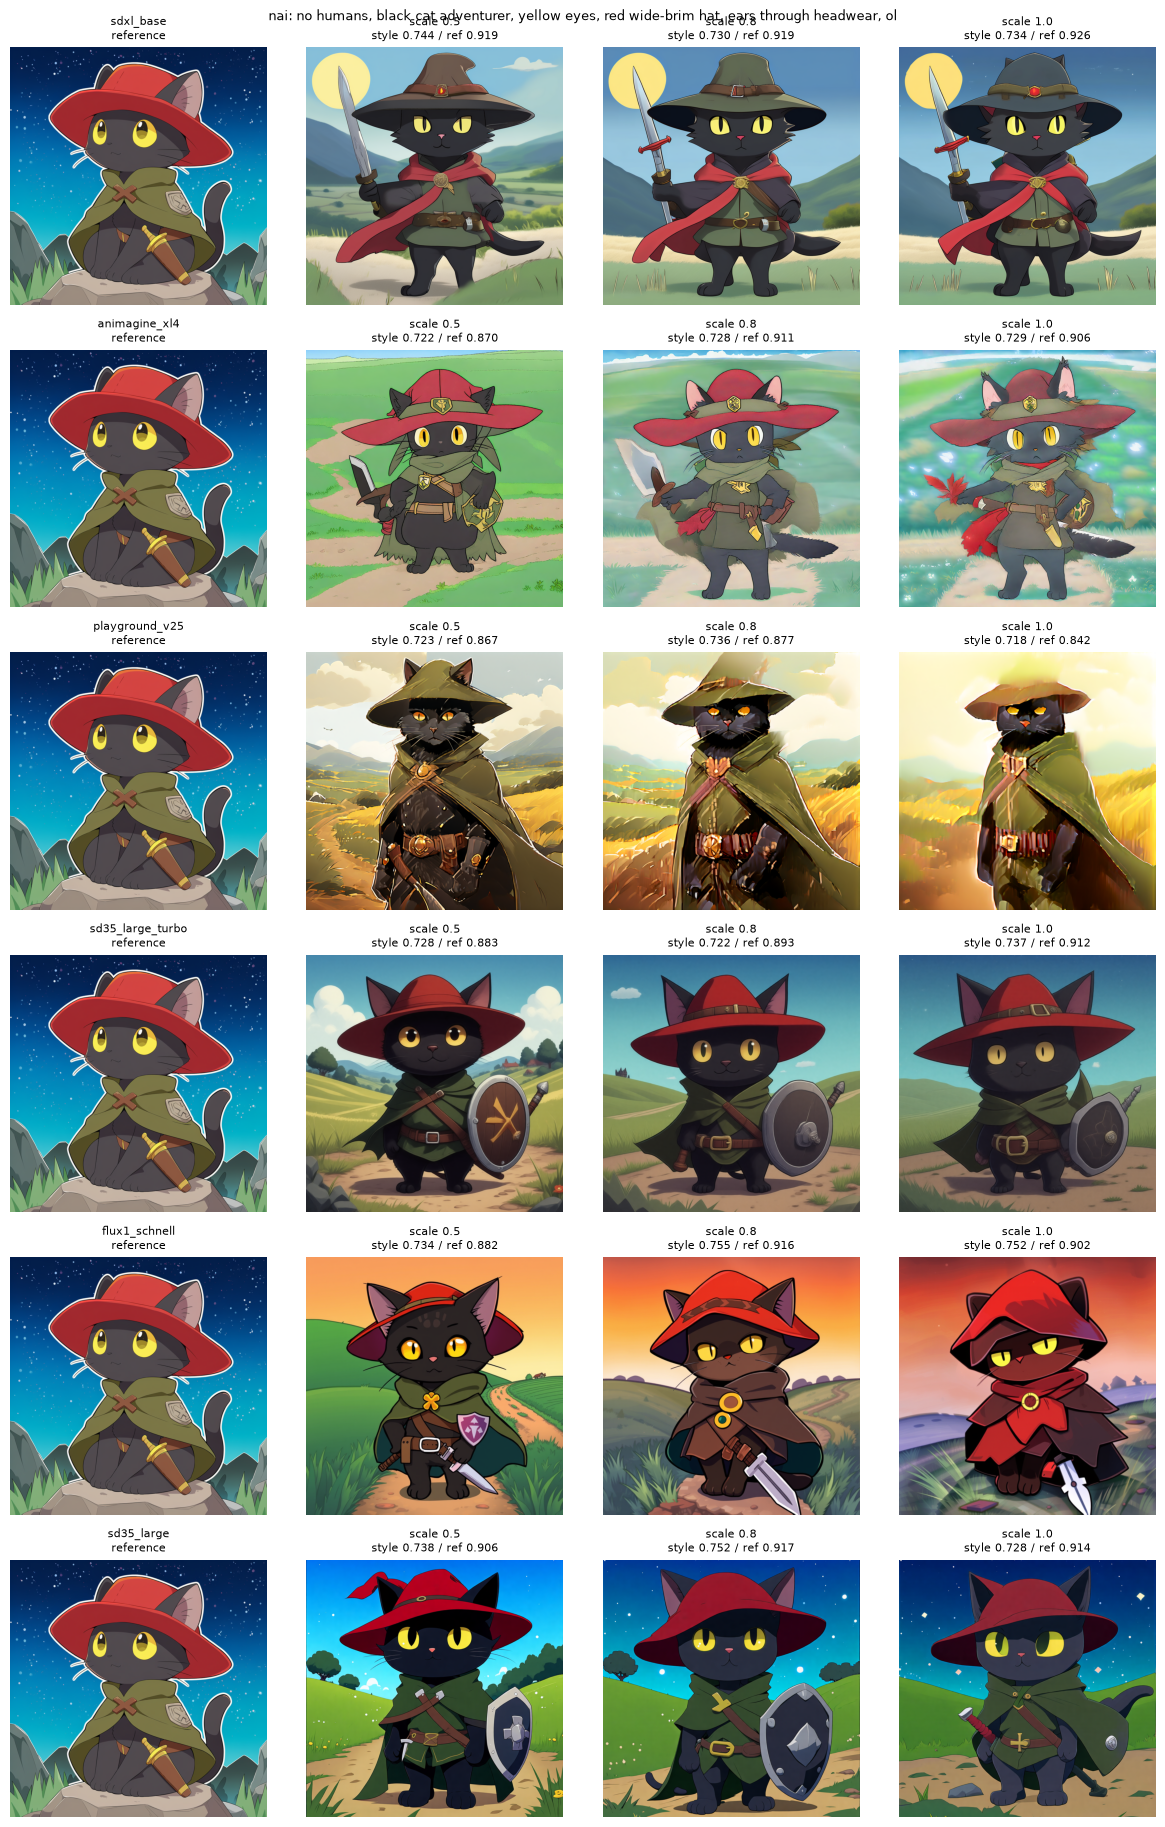

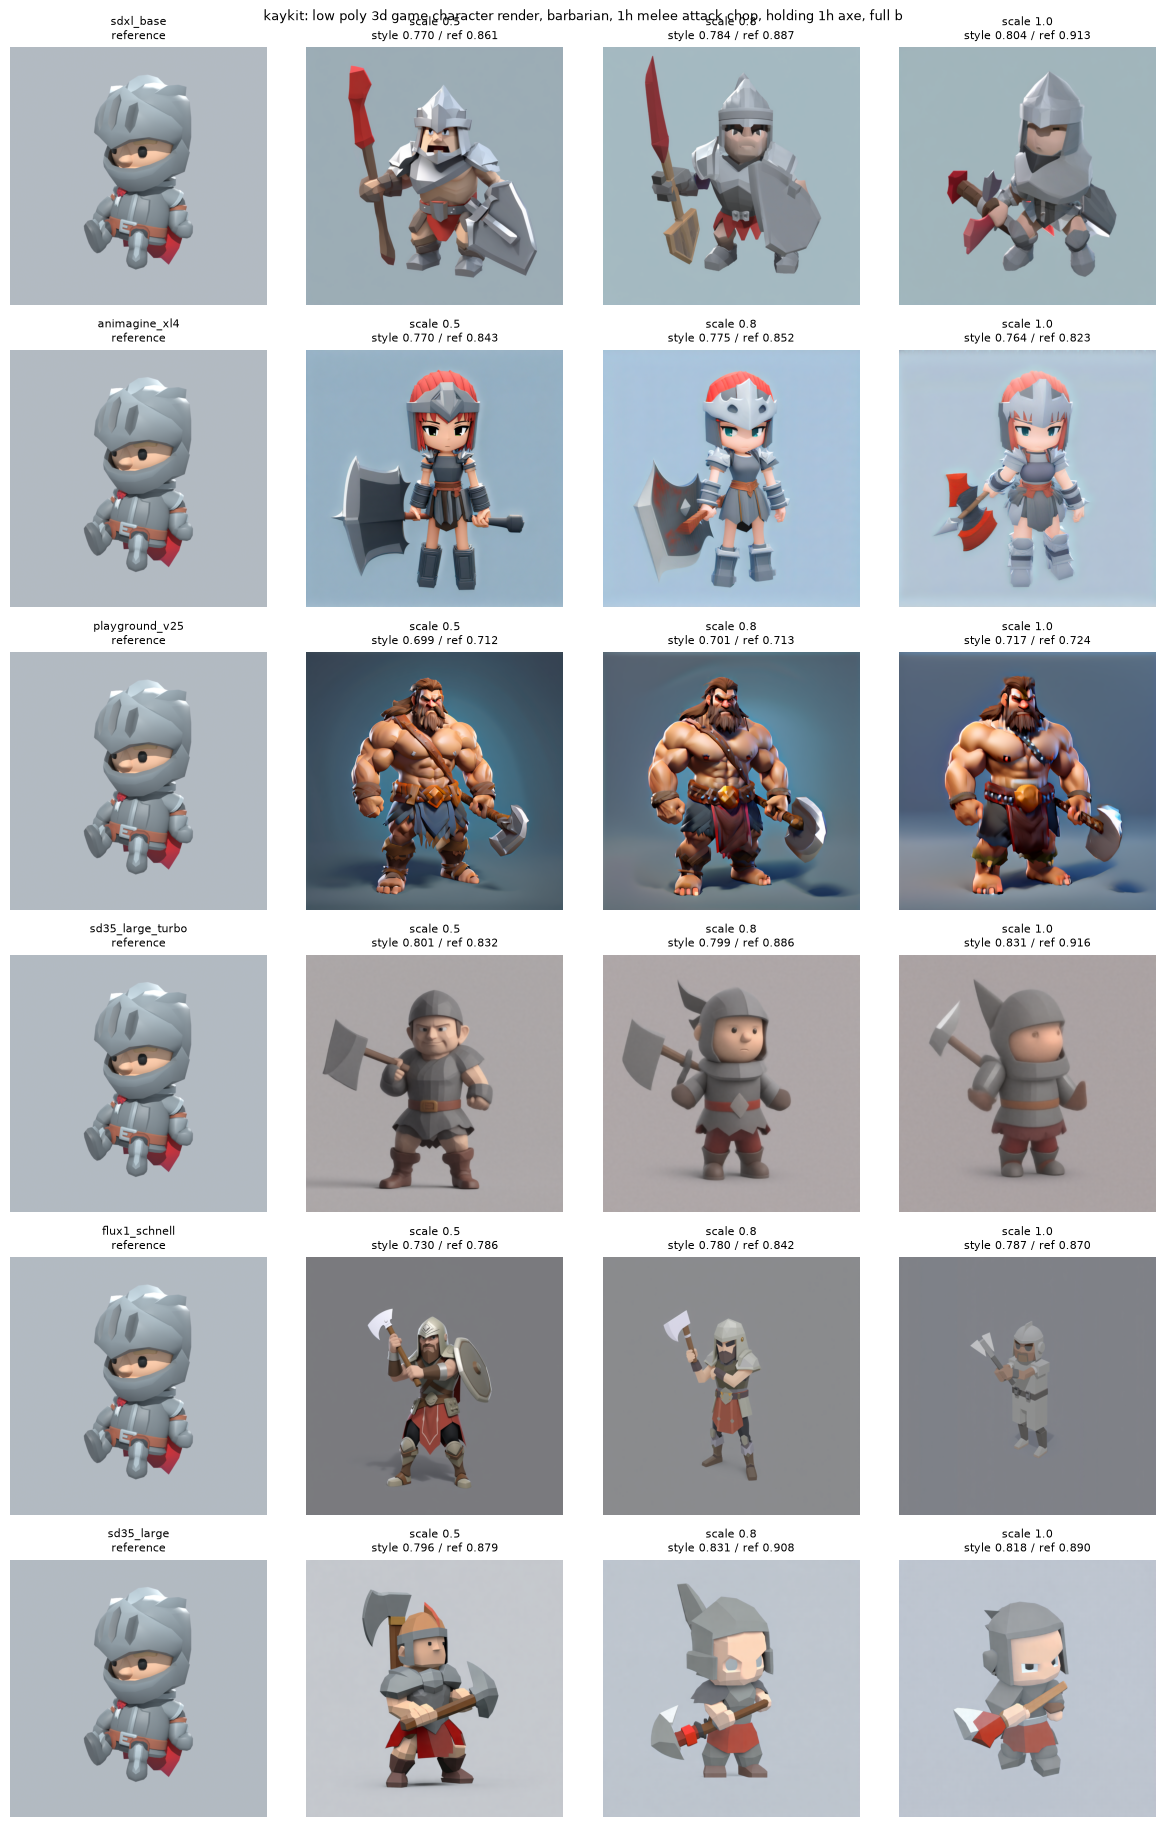

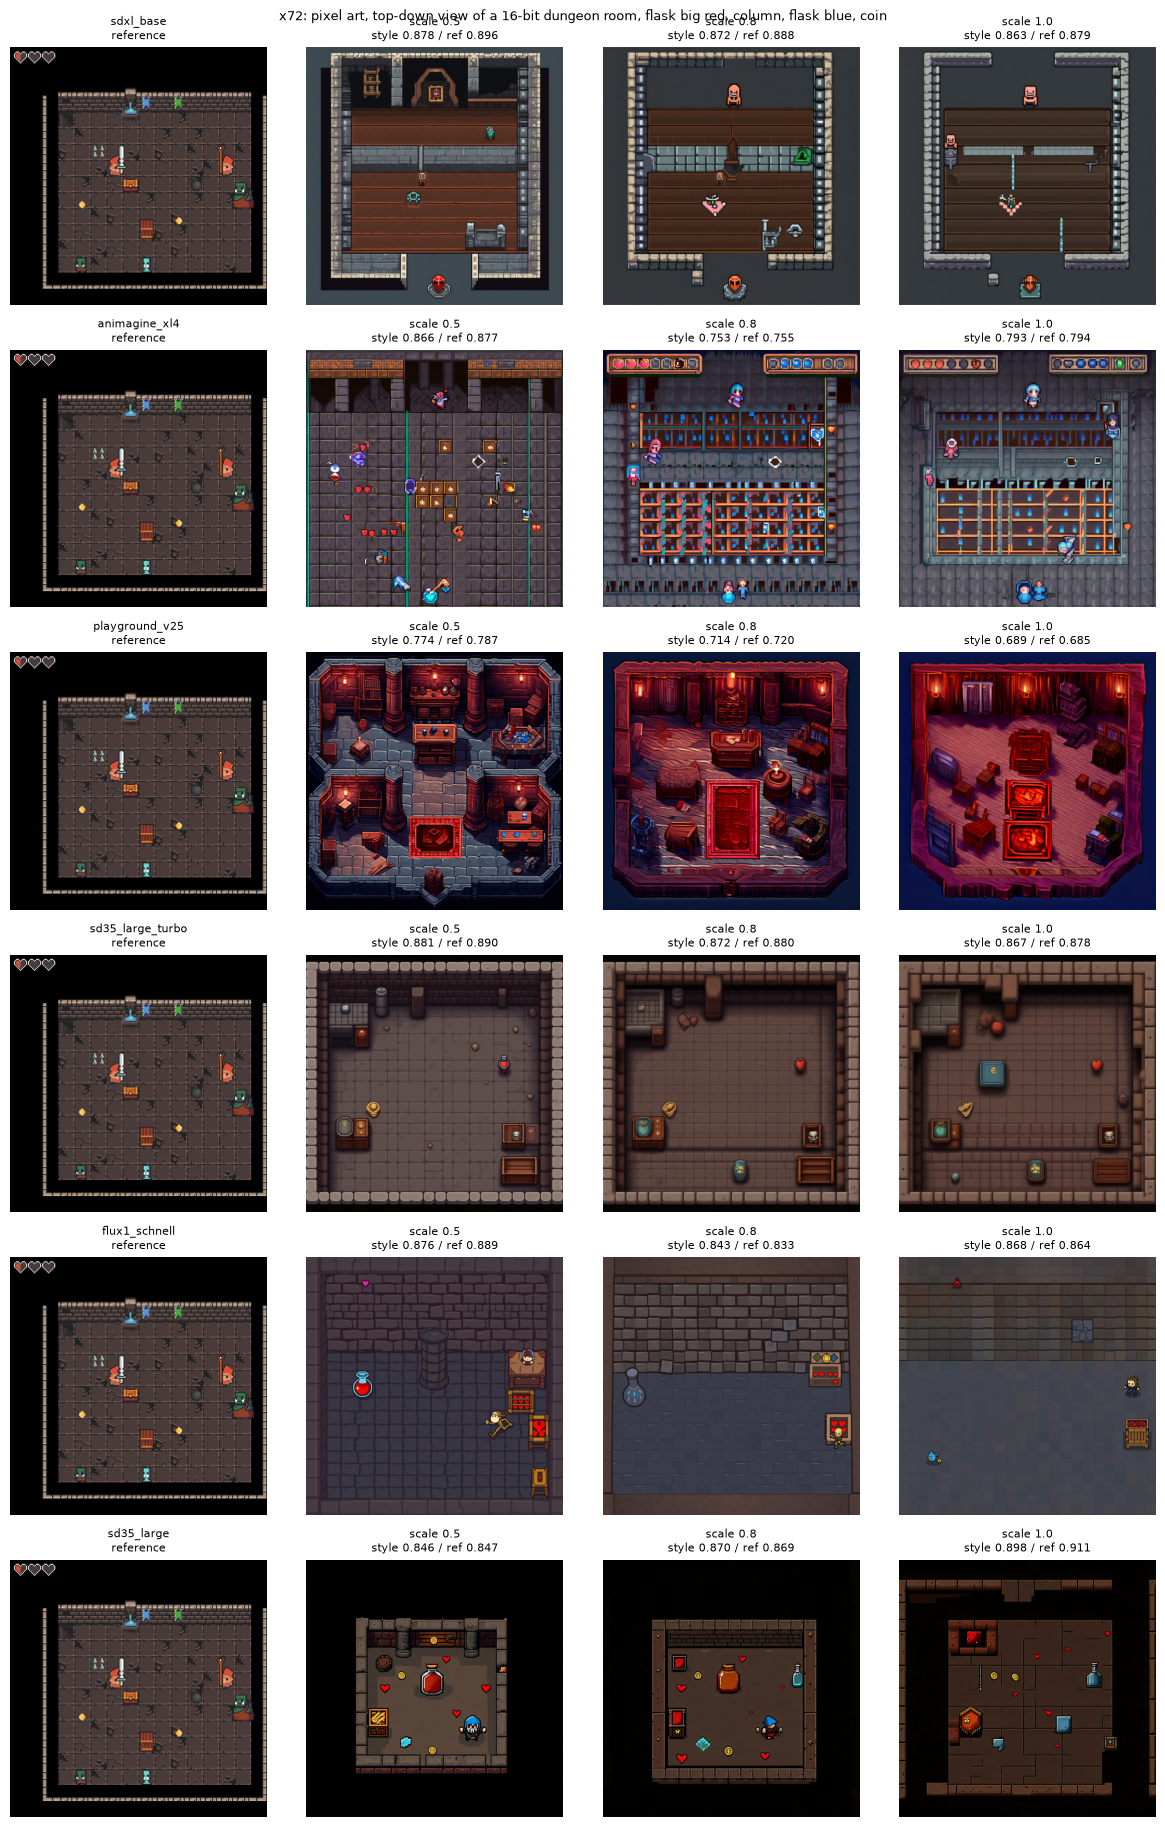

In [6]:
import matplotlib.pyplot as plt

games = list(GAME_DIRS)
models = list(MODELS)
fig, axes = plt.subplots(2, 3, figsize=(24, 10))
for c, g in enumerate(games):
    for r, (col, title) in enumerate([('style_sim', 'style similarity to held-out game images'),
                                      ('ref_sim', 'similarity to reference image')]):
        ax = axes[r, c]
        s = summary[summary.game == g]
        w = 0.8 / len(SCALES)
        for i, sc in enumerate(SCALES):
            v = s[s.scale == sc].set_index('model').reindex(models)[col]
            ax.bar(np.arange(len(models)) + i * w, v, w, label=f'scale {sc}')
        if col == 'style_sim':
            ax.axhline(base[g], color='black', linestyle='--', label='game internal mean')
        ax.set_xticks(np.arange(len(models)) + w, models, rotation=30, fontsize=8)
        ax.set_title(f'{g}: {title}')
        ax.set_ylim(0.4, 1.0)
        ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUT_DIR / 'ipa_sim_bars.png', dpi=90)
plt.show()

# 게임별 그리드: 행 = 모델, 열 = 참조 이미지 + 강도별(seed 0)
for g in games:
    fig, axes = plt.subplots(len(models), len(SCALES) + 1, figsize=(3 * (len(SCALES) + 1), 3.1 * len(models)), squeeze=False)
    for r, m in enumerate(models):
        axes[r, 0].imshow(Image.open(REFS[g]).convert('RGB'))
        axes[r, 0].set_title(f'{m}\nreference', fontsize=8)
        for c, sc in enumerate(SCALES):
            ax = axes[r, c + 1]
            row = rec[(rec.model == m) & (rec.game == g) & (rec.scale == sc) & (rec.seed == SEEDS[0])]
            if len(row):
                ax.imshow(Image.open(OUT_DIR / row.iloc[0].file))
                ax.set_title(f'scale {sc}\nstyle {row.iloc[0].style_sim:.3f} / ref {row.iloc[0].ref_sim:.3f}', fontsize=8)
            else:
                ax.set_title(f'scale {sc}\nmissing', fontsize=8, color='red')
        for ax in axes[r]:
            ax.axis('off')
    plt.suptitle(f'{g}: {PROMPTS[g][:90]}', fontsize=9)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'ipa_grid_{g}.png', dpi=70)
    plt.show()